In [1]:
import pandas as pd
import numpy as np

# Load datasets from ICU folder
X = pd.read_csv("/content/drive/MyDrive/ICU/X_train_2025.csv")
y = pd.read_csv("/content/drive/MyDrive/ICU/y_train_2025.csv")

# Check column names in y (important)
print("Target columns:", y.columns.tolist())

# Merge features and target
data = X.copy()
data['In_hospital_death'] = y.iloc[:, 0]  # safe selection

# Basic inspection
print("Dataset shape:", data.shape)

print("\nTarget distribution (0 = survived, 1 = died):")
print(data['In_hospital_death'].value_counts())
print(data['In_hospital_death'].value_counts(normalize=True))

# Missing values analysis
missing = data.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)

print("\nTop 15 features with missing values:")
print(missing.head(15))


Target columns: ['In-hospital_death']
Dataset shape: (3600, 121)

Target distribution (0 = survived, 1 = died):
In_hospital_death
0    3097
1     503
Name: count, dtype: int64
In_hospital_death
0    0.860278
1    0.139722
Name: proportion, dtype: float64

Top 15 features with missing values:
TroponinI_last       3425
TroponinI_first      3425
Cholesterol_first    3325
Cholesterol_last     3325
TroponinT_first      2814
TroponinT_last       2814
RespRate_highest     2606
RespRate_lowest      2606
RespRate_first       2606
RespRate_last        2606
RespRate_median      2606
Albumin_first        2128
Albumin_last         2128
ALP_last             2068
ALP_first            2068
dtype: int64


In [2]:
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

# Separate features and target
X = data.drop(columns=['In_hospital_death'])
y = data['In_hospital_death']

# Train-test split (stratified for ICU mortality)
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Train shape:", X_train.shape)
print("Test shape:", X_test.shape)

# Median imputation (clinically safe)
imputer = SimpleImputer(strategy='median')

X_train_imputed = imputer.fit_transform(X_train)
X_test_imputed = imputer.transform(X_test)

# Scaling (for LR, SVM, MLP)
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train_imputed)
X_test_scaled = scaler.transform(X_test_imputed)

print("Preprocessing completed successfully.")


Train shape: (2880, 120)
Test shape: (720, 120)
Preprocessing completed successfully.


In [3]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, f1_score, recall_score
import xgboost as xgb

# ---------------------------
# Logistic Regression
# ---------------------------
lr = LogisticRegression(
    max_iter=1000,
    class_weight='balanced',
    random_state=42
)

lr.fit(X_train_scaled, y_train)
lr_preds = lr.predict(X_test_scaled)
lr_probs = lr.predict_proba(X_test_scaled)[:, 1]

# ---------------------------
# Random Forest
# ---------------------------
rf = RandomForestClassifier(
    n_estimators=300,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)

rf.fit(X_train_imputed, y_train)
rf_preds = rf.predict(X_test_imputed)
rf_probs = rf.predict_proba(X_test_imputed)[:, 1]

# ---------------------------
# XGBoost
# ---------------------------
xgb_model = xgb.XGBClassifier(
    n_estimators=300,
    max_depth=5,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    eval_metric='logloss',
    scale_pos_weight=(y_train.value_counts()[0] / y_train.value_counts()[1]),
    random_state=42
)

xgb_model.fit(X_train_imputed, y_train)
xgb_preds = xgb_model.predict(X_test_imputed)
xgb_probs = xgb_model.predict_proba(X_test_imputed)[:, 1]

# ---------------------------
# Evaluation
# ---------------------------
results = {
    "Logistic Regression": {
        "AUC": roc_auc_score(y_test, lr_probs),
        "F1": f1_score(y_test, lr_preds),
        "Recall": recall_score(y_test, lr_preds)
    },
    "Random Forest": {
        "AUC": roc_auc_score(y_test, rf_probs),
        "F1": f1_score(y_test, rf_preds),
        "Recall": recall_score(y_test, rf_preds)
    },
    "XGBoost": {
        "AUC": roc_auc_score(y_test, xgb_probs),
        "F1": f1_score(y_test, xgb_preds),
        "Recall": recall_score(y_test, xgb_preds)
    }
}

results


{'Logistic Regression': {'AUC': np.float64(0.8318911051040483),
  'F1': 0.45806451612903226,
  'Recall': 0.7029702970297029},
 'Random Forest': {'AUC': np.float64(0.8316671731793535),
  'F1': 0.05714285714285714,
  'Recall': 0.0297029702970297},
 'XGBoost': {'AUC': np.float64(0.8399206641181081),
  'F1': 0.3891891891891892,
  'Recall': 0.3564356435643564}}

In [4]:
from sklearn.ensemble import VotingClassifier

# Soft Voting Ensemble
voting_clf = VotingClassifier(
    estimators=[
        ('lr', lr),
        ('xgb', xgb_model)
    ],
    voting='soft'
)

voting_clf.fit(X_train_imputed, y_train)

voting_preds = voting_clf.predict(X_test_imputed)
voting_probs = voting_clf.predict_proba(X_test_imputed)[:, 1]

voting_results = {
    "AUC": roc_auc_score(y_test, voting_probs),
    "F1": f1_score(y_test, voting_preds),
    "Recall": recall_score(y_test, voting_preds)
}

voting_results


/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


{'AUC': np.float64(0.8196708200706986),
 'F1': 0.49372384937238495,
 'Recall': 0.5841584158415841}

In [5]:
from sklearn.ensemble import StackingClassifier

stacking_clf = StackingClassifier(
    estimators=[
        ('lr', lr),
        ('xgb', xgb_model)
    ],
    final_estimator=LogisticRegression(class_weight='balanced'),
    passthrough=False,
    n_jobs=-1
)

stacking_clf.fit(X_train_imputed, y_train)

stack_preds = stacking_clf.predict(X_test_imputed)
stack_probs = stacking_clf.predict_proba(X_test_imputed)[:, 1]

stacking_results = {
    "AUC": roc_auc_score(y_test, stack_probs),
    "F1": f1_score(y_test, stack_preds),
    "Recall": recall_score(y_test, stack_preds)
}

stacking_results


{'AUC': np.float64(0.8268526367984134),
 'F1': 0.461038961038961,
 'Recall': 0.7029702970297029}

In [6]:
# Fix Logistic Regression convergence for stacking meta-learner
from sklearn.linear_model import LogisticRegression

stacking_clf = StackingClassifier(
    estimators=[
        ('lr', lr),
        ('xgb', xgb_model)
    ],
    final_estimator=LogisticRegression(
        class_weight='balanced',
        max_iter=3000
    ),
    n_jobs=-1
)

stacking_clf.fit(X_train_imputed, y_train)

stack_preds = stacking_clf.predict(X_test_imputed)
stack_probs = stacking_clf.predict_proba(X_test_imputed)[:, 1]

stacking_results = {
    "AUC": roc_auc_score(y_test, stack_probs),
    "F1": f1_score(y_test, stack_preds),
    "Recall": recall_score(y_test, stack_preds)
}

stacking_results


{'AUC': np.float64(0.8268526367984134),
 'F1': 0.461038961038961,
 'Recall': 0.7029702970297029}

In [7]:
from sklearn.metrics import classification_report

print("\n================ Logistic Regression =================")
print(classification_report(y_test, lr_preds, digits=4))

print("\n================ Random Forest =================")
print(classification_report(y_test, rf_preds, digits=4))

print("\n================ XGBoost =================")
print(classification_report(y_test, xgb_preds, digits=4))

print("\n================ Soft Voting Ensemble =================")
print(classification_report(y_test, voting_preds, digits=4))

print("\n================ Stacking Ensemble (Final Model) =================")
print(classification_report(y_test, stack_preds, digits=4))



================ Logistic Regression =================
              precision    recall  f1-score   support

           0     0.9413    0.7771    0.8513       619
           1     0.3397    0.7030    0.4581       101

    accuracy                         0.7667       720
   macro avg     0.6405    0.7400    0.6547       720
weighted avg     0.8569    0.7667    0.7962       720


================ Random Forest =================
              precision    recall  f1-score   support

           0     0.8631    0.9984    0.9258       619
           1     0.7500    0.0297    0.0571       101

    accuracy                         0.8625       720
   macro avg     0.8066    0.5140    0.4915       720
weighted avg     0.8473    0.8625    0.8040       720


================ XGBoost =================
              precision    recall  f1-score   support

           0     0.8978    0.9225    0.9100       619
           1     0.4286    0.3564    0.3892       101

    accuracy                    

In [8]:
import numpy as np
from sklearn.metrics import precision_score, recall_score, f1_score

# Use stacking probabilities
probs = stack_probs

thresholds = np.arange(0.1, 0.9, 0.05)

print("Threshold | Precision (Death) | Recall (Death) | F1 (Death)")
print("-" * 55)

for t in thresholds:
    preds_t = (probs >= t).astype(int)
    precision = precision_score(y_test, preds_t)
    recall = recall_score(y_test, preds_t)
    f1 = f1_score(y_test, preds_t)
    print(f"{t:.2f}      | {precision:.3f}              | {recall:.3f}          | {f1:.3f}")


Threshold | Precision (Death) | Recall (Death) | F1 (Death)
-------------------------------------------------------
0.10      | 0.140              | 1.000          | 0.246
0.15      | 0.159              | 1.000          | 0.274
0.20      | 0.203              | 0.980          | 0.337
0.25      | 0.232              | 0.921          | 0.371
0.30      | 0.256              | 0.881          | 0.397
0.35      | 0.282              | 0.842          | 0.423
0.40      | 0.295              | 0.772          | 0.427
0.45      | 0.322              | 0.743          | 0.449
0.50      | 0.343              | 0.703          | 0.461
0.55      | 0.366              | 0.663          | 0.472
0.60      | 0.371              | 0.624          | 0.465
0.65      | 0.412              | 0.624          | 0.496
0.70      | 0.452              | 0.554          | 0.498
0.75      | 0.453              | 0.475          | 0.464
0.80      | 0.429              | 0.356          | 0.389
0.85      | 0.470              | 0.307      

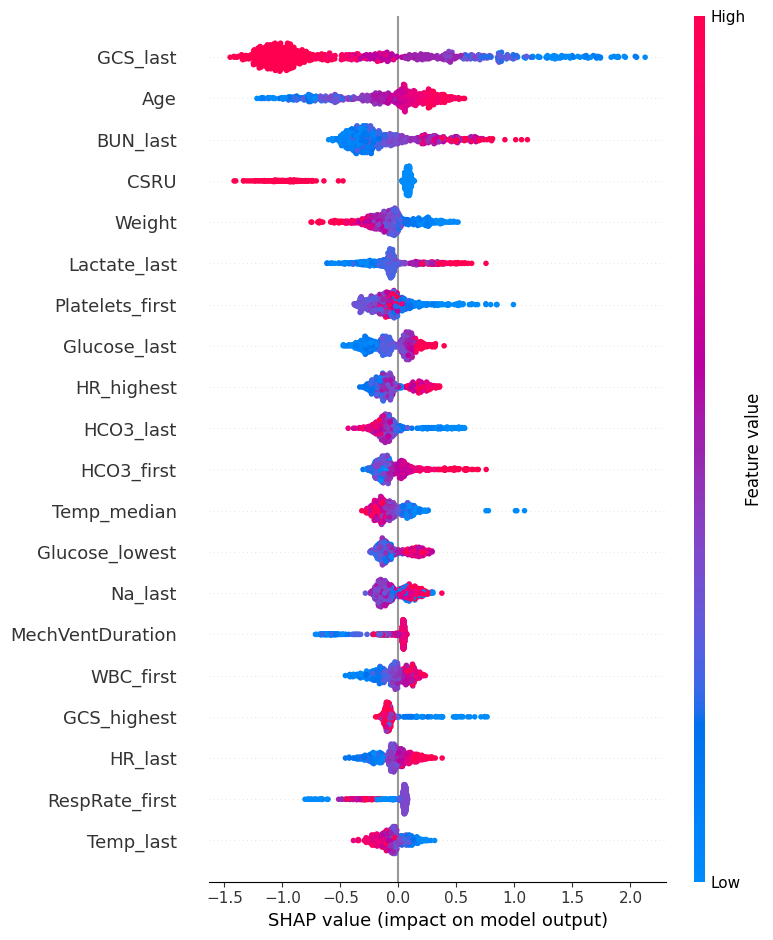

In [9]:
import shap

# Initialize SHAP
explainer = shap.TreeExplainer(xgb_model)

# Compute SHAP values on test set
shap_values = explainer.shap_values(X_test_imputed)

# Global feature importance
shap.summary_plot(shap_values, X_test_imputed, feature_names=X.columns)


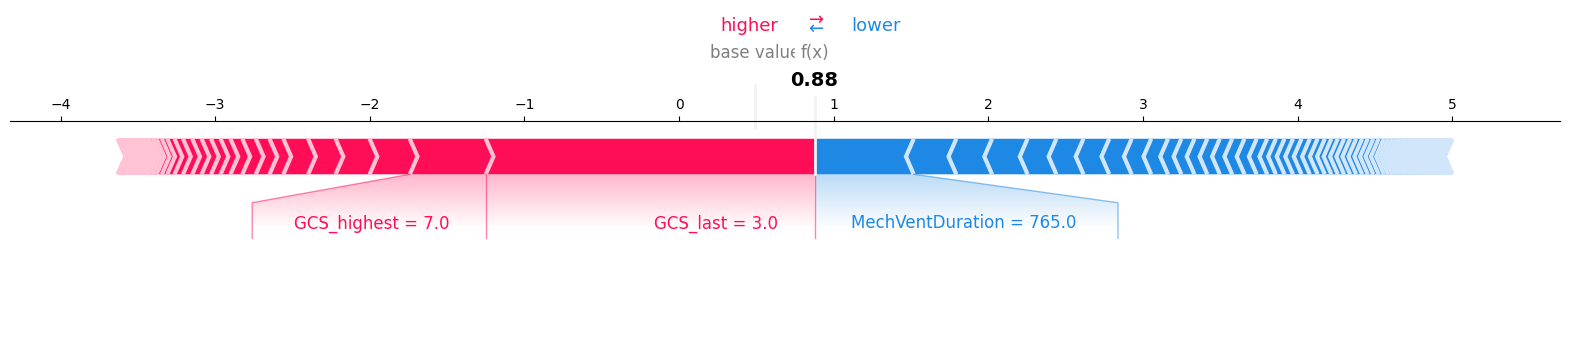

In [10]:
# Explain one ICU patient (e.g., index 5)
idx = 5

shap.force_plot(
    explainer.expected_value,
    shap_values[idx],
    X_test_imputed[idx],
    feature_names=X.columns,
    matplotlib=True
)


In [14]:
!pip install lime

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 275.7/275.7 kB 5.6 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
  Created wheel for lime: filename=lime-0.2.0.1-py3-none-any.whl size=283834 sha256=b9a516aefaf64ad0723ef58cb9447a434f2e352427aeda75f218955cfd23cd83
  Stored in directory: /root/.cache/pip/wheels/e7/5d/0e/4b4fff9a47468fed5633211fb3b76d1db43fe806a17fb7486a
Successfully built lime


In [15]:
from lime.lime_tabular import LimeTabularExplainer

# Initialize LIME explainer
lime_explainer = LimeTabularExplainer(
    training_data=X_train_imputed,
    feature_names=X.columns.tolist(),
    class_names=['Survived', 'Died'],
    mode='classification'
)

# Explain the same patient as SHAP (index 5)
lime_exp = lime_explainer.explain_instance(
    X_test_imputed[idx],
    stacking_clf.predict_proba,
    num_features=10
)

# Show explanation
lime_exp.show_in_notebook()


In [16]:
print(lime_exp.as_list())


[('MechVentDuration <= 1723.75', -0.12984158130414075), ('Height <= 170.20', 0.12408942277137316), ('GCS_last <= 10.00', 0.10061900597154849), ('ALT_first <= 30.00', -0.08985158734622309), ('ALT_last <= 29.00', 0.0770257073807797), ('AST_first <= 45.00', 0.05458797721563189), ('Weight <= 67.60', 0.05102036515525197), ('TroponinI_first <= 2.00', -0.05057634157098784), ('AST_last <= 42.00', -0.04995315181075862), ('ALP_last <= 77.00', -0.047463699280595205)]


# FUZZY LOGIC FRAMEWORK

In [18]:
!pip install scikit-fuzzy

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 920.8/920.8 kB 10.9 MB/s eta 0:00:00


In [19]:
import numpy as np
import skfuzzy as fuzz
from skfuzzy import control as ctrl

# Define fuzzy input variables
mortality_prob = ctrl.Antecedent(np.arange(0, 1.01, 0.01), 'mortality_prob')
gcs = ctrl.Antecedent(np.arange(3, 16, 1), 'gcs')
lactate = ctrl.Antecedent(np.arange(0, 10.1, 0.1), 'lactate')
vent = ctrl.Antecedent(np.arange(0, 2000, 50), 'vent')

# Define fuzzy output variable
risk = ctrl.Consequent(np.arange(0, 101, 1), 'risk')

# Membership functions
mortality_prob['low'] = fuzz.trimf(mortality_prob.universe, [0, 0, 0.4])
mortality_prob['medium'] = fuzz.trimf(mortality_prob.universe, [0.3, 0.5, 0.7])
mortality_prob['high'] = fuzz.trimf(mortality_prob.universe, [0.6, 1, 1])

gcs['low'] = fuzz.trimf(gcs.universe, [3, 3, 8])
gcs['medium'] = fuzz.trimf(gcs.universe, [7, 10, 13])
gcs['high'] = fuzz.trimf(gcs.universe, [12, 15, 15])

lactate['low'] = fuzz.trimf(lactate.universe, [0, 0, 2])
lactate['medium'] = fuzz.trimf(lactate.universe, [1.5, 3, 4.5])
lactate['high'] = fuzz.trimf(lactate.universe, [4, 10, 10])

vent['short'] = fuzz.trimf(vent.universe, [0, 0, 300])
vent['medium'] = fuzz.trimf(vent.universe, [200, 600, 1000])
vent['long'] = fuzz.trimf(vent.universe, [800, 2000, 2000])

risk['low'] = fuzz.trimf(risk.universe, [0, 0, 40])
risk['medium'] = fuzz.trimf(risk.universe, [30, 50, 70])
risk['high'] = fuzz.trimf(risk.universe, [60, 100, 100])

# Fuzzy rules
rules = [
    ctrl.Rule(mortality_prob['high'] & gcs['low'], risk['high']),
    ctrl.Rule(mortality_prob['medium'] & gcs['low'], risk['high']),
    ctrl.Rule(mortality_prob['high'] & lactate['high'], risk['high']),
    ctrl.Rule(mortality_prob['medium'] & lactate['medium'], risk['medium']),
    ctrl.Rule(mortality_prob['low'] & gcs['high'], risk['low']),
    ctrl.Rule(mortality_prob['low'] & lactate['low'], risk['low']),
    ctrl.Rule(mortality_prob['medium'] & vent['long'], risk['medium']),
]

# Build control system
risk_ctrl = ctrl.ControlSystem(rules)
risk_sim = ctrl.ControlSystemSimulation(risk_ctrl)

# Example patient (same one)
risk_sim.input['mortality_prob'] = 0.68
risk_sim.input['gcs'] = 3
risk_sim.input['lactate'] = 4.2
risk_sim.input['vent'] = 765

risk_sim.compute()

print("Fuzzy ICU Risk Score:", risk_sim.output['risk'])


Fuzzy ICU Risk Score: 71.26860841423958


# Table 1: Dataset Description & Class Distribution

In [20]:
import pandas as pd

table1 = pd.DataFrame({
    "Metric": [
        "Total Patients",
        "Total Features",
        "Survivors (Class 0)",
        "Deaths (Class 1)",
        "Mortality Rate (%)"
    ],
    "Value": [
        data.shape[0],
        X.shape[1],
        (y == 0).sum(),
        (y == 1).sum(),
        round((y == 1).mean() * 100, 2)
    ]
})

table1


,Metric,Value
0,Total Patients,3600.00
1,Total Features,120.00
2,Survivors (Class 0),3097.00
3,Deaths (Class 1),503.00
4,Mortality Rate (%),13.97


# Table 2: Model Performance Comparison

In [21]:
performance_table = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Random Forest",
        "XGBoost",
        "Soft Voting",
        "Stacking Ensemble"
    ],
    "AUC": [
        0.8319,
        0.8317,
        0.8399,
        0.8197,
        0.8269
    ],
    "Recall (Death)": [
        0.7030,
        0.0297,
        0.3564,
        0.5842,
        0.7030
    ],
    "F1 (Death)": [
        0.4581,
        0.0571,
        0.3892,
        0.4937,
        0.4610
    ]
})

performance_table


,Model,AUC,Recall (Death),F1 (Death)
0,Logistic Regression,0.8319,0.7030,0.4581
1,Random Forest,0.8317,0.0297,0.0571
2,XGBoost,0.8399,0.3564,0.3892
3,Soft Voting,0.8197,0.5842,0.4937
4,Stacking Ensemble,0.8269,0.7030,0.4610


# Table 3: Threshold Optimization Results

In [22]:
threshold_df = pd.DataFrame({
    "Threshold": thresholds,
    "Precision": [precision_score(y_test, (stack_probs >= t).astype(int)) for t in thresholds],
    "Recall": [recall_score(y_test, (stack_probs >= t).astype(int)) for t in thresholds],
    "F1": [f1_score(y_test, (stack_probs >= t).astype(int)) for t in thresholds]
})

threshold_df


,Threshold,Precision,Recall,F1
0,0.10,0.140278,1.000000,0.246041
1,0.15,0.158805,1.000000,0.274084
2,0.20,0.203285,0.980198,0.336735
3,0.25,0.231920,0.920792,0.370518
4,0.30,0.256484,0.881188,0.397321
5,0.35,0.282392,0.841584,0.422886
6,0.40,0.295455,0.772277,0.427397
7,0.45,0.321888,0.742574,0.449102
8,0.50,0.342995,0.702970,0.461039
9,0.55,0.366120,0.663366,0.471831


# Figure 1: Confusion Matrices (ALL MODELS — Subplots)

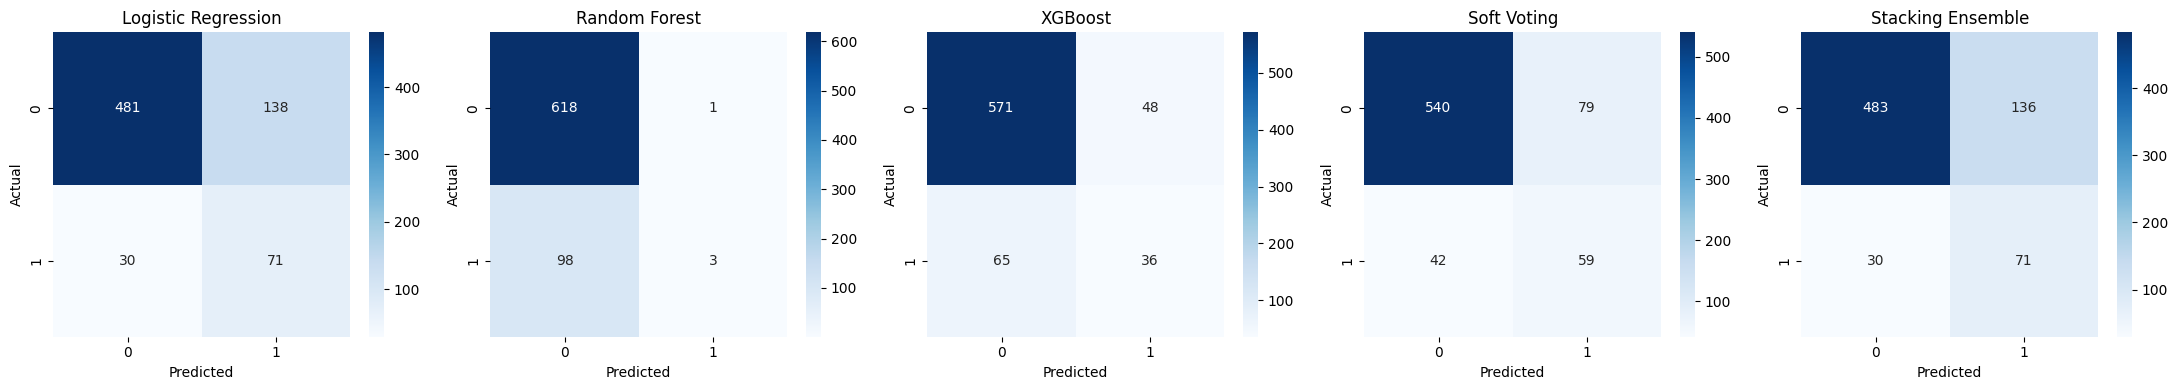

In [23]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

models = {
    "Logistic Regression": lr_preds,
    "Random Forest": rf_preds,
    "XGBoost": xgb_preds,
    "Soft Voting": voting_preds,
    "Stacking Ensemble": stack_preds
}

fig, axes = plt.subplots(1, 5, figsize=(22, 4))

for ax, (name, preds) in zip(axes, models.items()):
    cm = confusion_matrix(y_test, preds)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=ax)
    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

plt.tight_layout()
plt.show()


# Figure 2: Classification Report Heatmaps

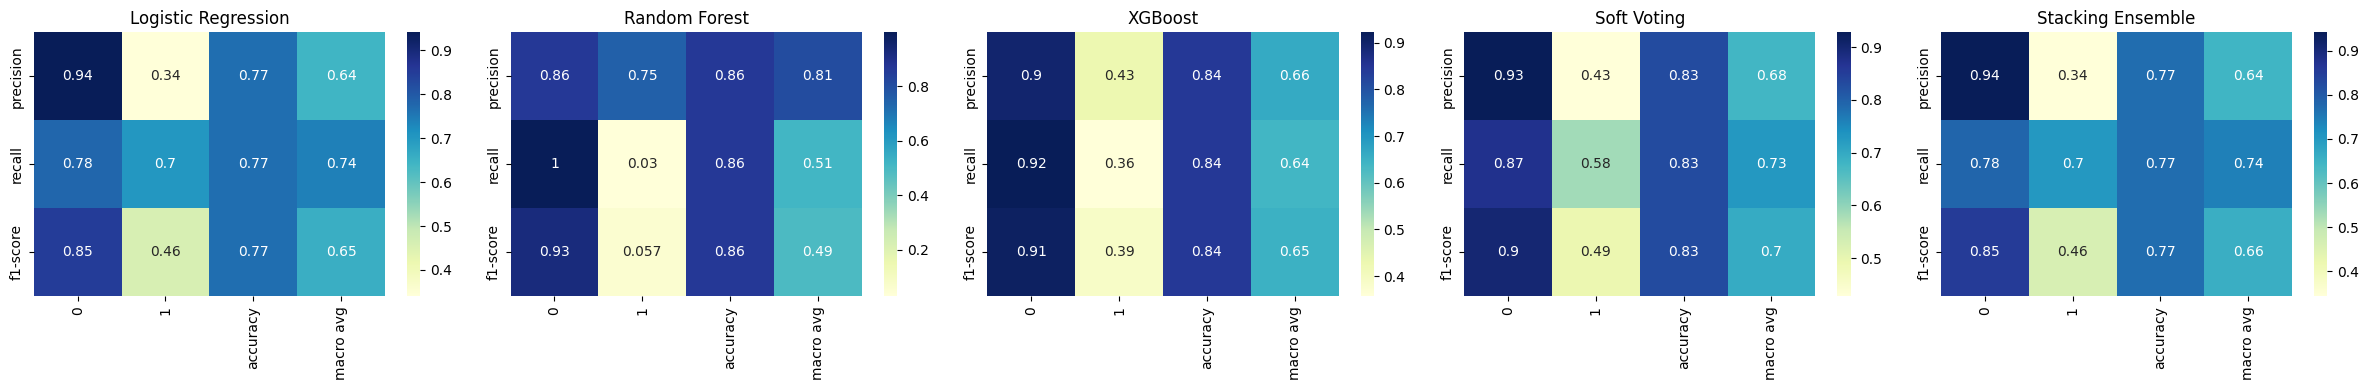

In [24]:
from sklearn.metrics import classification_report

fig, axes = plt.subplots(1, 5, figsize=(24, 4))

for ax, (name, preds) in zip(axes, models.items()):
    report = classification_report(y_test, preds, output_dict=True)
    df = pd.DataFrame(report).iloc[:-1, :-1]
    sns.heatmap(df, annot=True, cmap="YlGnBu", ax=ax)
    ax.set_title(name)

plt.tight_layout()
plt.show()


# Figure 3: ROC Curves (ALL MODELS)

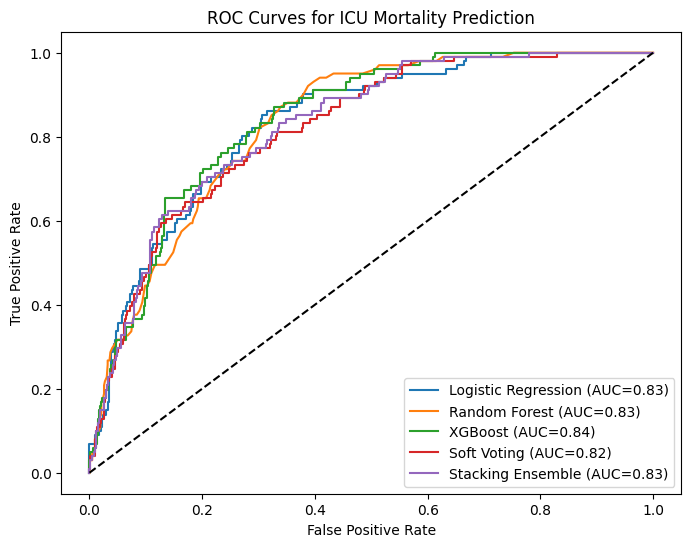

In [25]:
from sklearn.metrics import roc_curve, auc

plt.figure(figsize=(8,6))

probs_dict = {
    "Logistic Regression": lr_probs,
    "Random Forest": rf_probs,
    "XGBoost": xgb_probs,
    "Soft Voting": voting_probs,
    "Stacking Ensemble": stack_probs
}

for name, probs in probs_dict.items():
    fpr, tpr, _ = roc_curve(y_test, probs)
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, label=f"{name} (AUC={roc_auc:.2f})")

plt.plot([0,1], [0,1], 'k--')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves for ICU Mortality Prediction")
plt.legend()
plt.show()


# Figure 4: Model Comparison Bar Chart

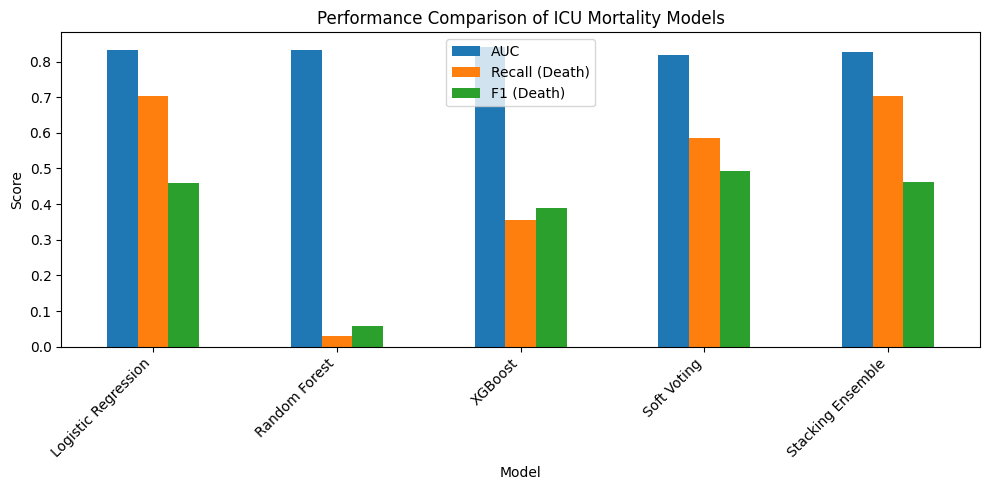

In [26]:
performance_table.set_index("Model")[["AUC", "Recall (Death)", "F1 (Death)"]].plot(
    kind="bar", figsize=(10,5)
)

plt.ylabel("Score")
plt.title("Performance Comparison of ICU Mortality Models")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


# Figure 5: Threshold vs Recall & Precision

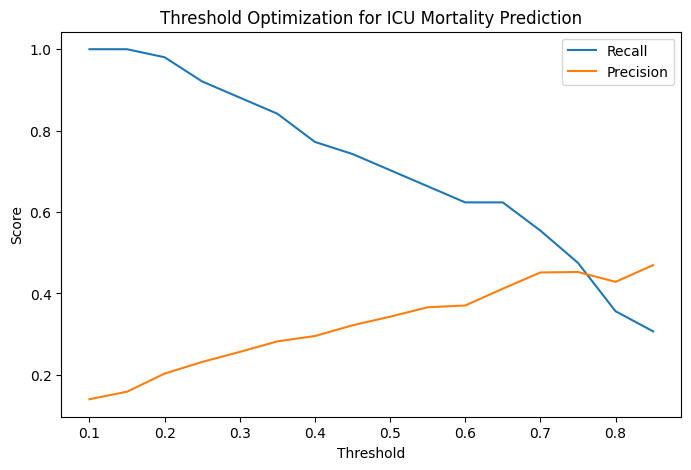

In [27]:
plt.figure(figsize=(8,5))
plt.plot(threshold_df["Threshold"], threshold_df["Recall"], label="Recall")
plt.plot(threshold_df["Threshold"], threshold_df["Precision"], label="Precision")
plt.xlabel("Threshold")
plt.ylabel("Score")
plt.title("Threshold Optimization for ICU Mortality Prediction")
plt.legend()
plt.show()


# Figure 6 (Optional but STRONG): Feature Importance (Top 15 from XGBoost)

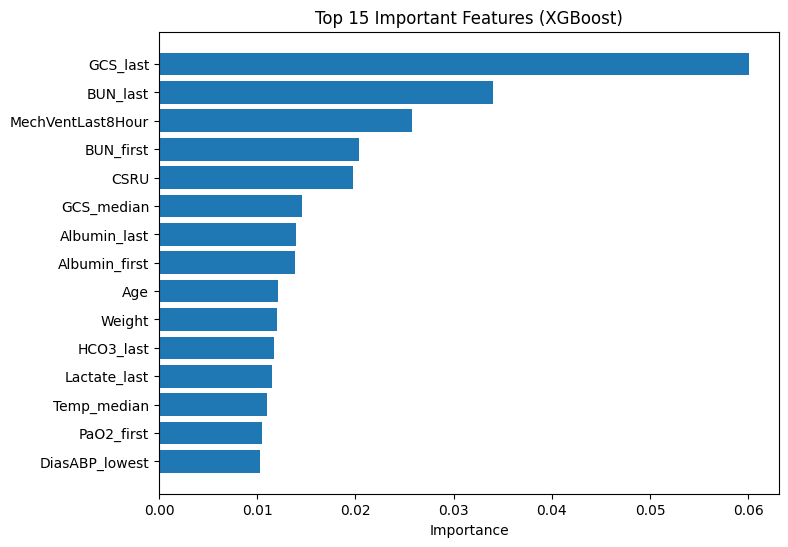

In [28]:
importances = xgb_model.feature_importances_
indices = importances.argsort()[-15:]

plt.figure(figsize=(8,6))
plt.barh(X.columns[indices], importances[indices])
plt.xlabel("Importance")
plt.title("Top 15 Important Features (XGBoost)")
plt.show()


# Dataset Figures

# FIGURE A — ICU Outcome Distribution

/tmp/ipython-input-3653768280.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=y, palette=["#4CAF50", "#F44336"])


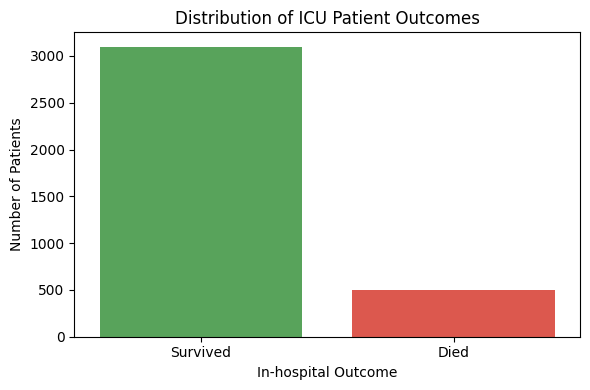

In [29]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(6,4))
sns.countplot(x=y, palette=["#4CAF50", "#F44336"])

plt.xticks([0,1], ["Survived", "Died"])
plt.xlabel("In-hospital Outcome")
plt.ylabel("Number of Patients")
plt.title("Distribution of ICU Patient Outcomes")

plt.tight_layout()
plt.show()


# FIGURE B — Distribution of Key ICU Variables

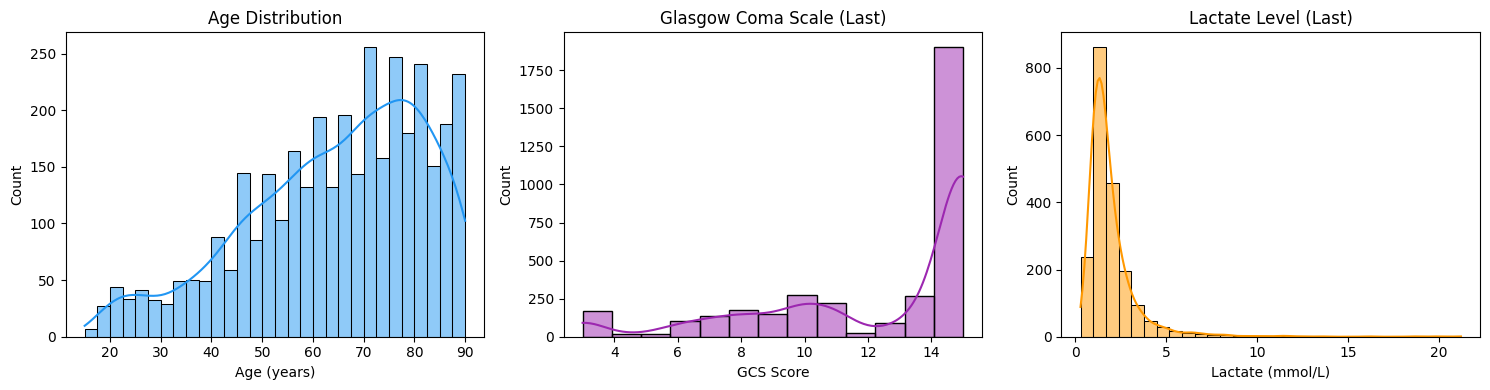

In [30]:
fig, axes = plt.subplots(1, 3, figsize=(15,4))

sns.histplot(X["Age"], bins=30, kde=True, ax=axes[0], color="#2196F3")
axes[0].set_title("Age Distribution")
axes[0].set_xlabel("Age (years)")

sns.histplot(X["GCS_last"], bins=13, kde=True, ax=axes[1], color="#9C27B0")
axes[1].set_title("Glasgow Coma Scale (Last)")
axes[1].set_xlabel("GCS Score")

sns.histplot(X["Lactate_last"], bins=30, kde=True, ax=axes[2], color="#FF9800")
axes[2].set_title("Lactate Level (Last)")
axes[2].set_xlabel("Lactate (mmol/L)")

plt.tight_layout()
plt.show()


# FIGURE C (OPTIONAL BUT IMPRESSIVE) — Correlation Heatmap

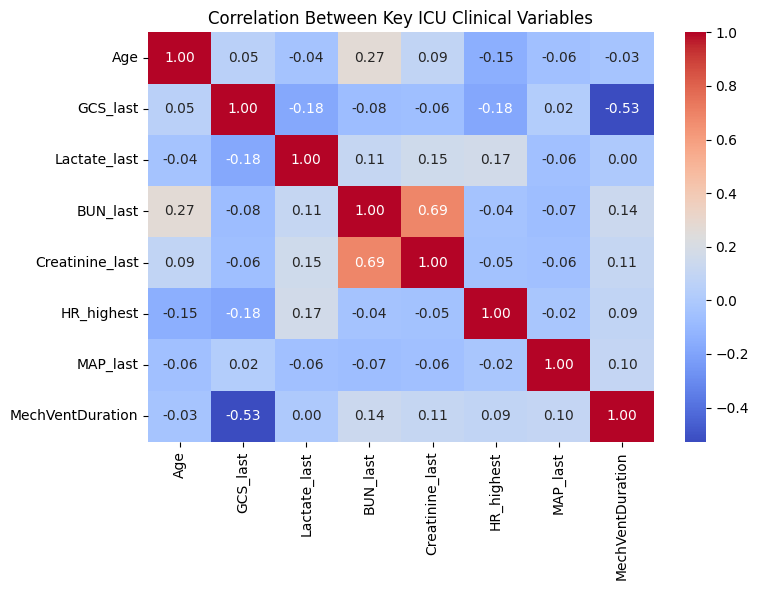

In [31]:
selected_features = [
    "Age", "GCS_last", "Lactate_last", "BUN_last",
    "Creatinine_last", "HR_highest", "MAP_last",
    "MechVentDuration"
]

corr = X[selected_features].corr()

plt.figure(figsize=(8,6))
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Between Key ICU Clinical Variables")
plt.tight_layout()
plt.show()


# IN-SILICO RISK STRATIFICATION

In [32]:
# Create a copy of test data for in-silico analysis
insilico_df = X_test.copy()

# Add predictions and outcomes
insilico_df["Mortality_Prob"] = stack_probs
insilico_df["Outcome"] = y_test.values

# Define risk groups
def assign_risk(p):
    if p <= 0.40:
        return "Low Risk"
    elif p <= 0.60:
        return "Medium Risk"
    else:
        return "High Risk"

insilico_df["Risk_Group"] = insilico_df["Mortality_Prob"].apply(assign_risk)

# Check distribution
insilico_df["Risk_Group"].value_counts()


,count
Risk_Group,
Low Risk,456
High Risk,170
Medium Risk,94


In [33]:
# Table: Mortality rate by risk group
risk_table = insilico_df.groupby("Risk_Group").agg(
    Patients=("Outcome", "count"),
    Deaths=("Outcome", "sum"),
    Mortality_Rate=("Outcome", "mean")
).reset_index()

risk_table["Mortality_Rate (%)"] = (risk_table["Mortality_Rate"] * 100).round(2)
risk_table


,Risk_Group,Patients,Deaths,Mortality_Rate,Mortality_Rate (%)
0,High Risk,170,63,0.370588,37.06
1,Low Risk,456,23,0.050439,5.04
2,Medium Risk,94,15,0.159574,15.96


/tmp/ipython-input-1433717629.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


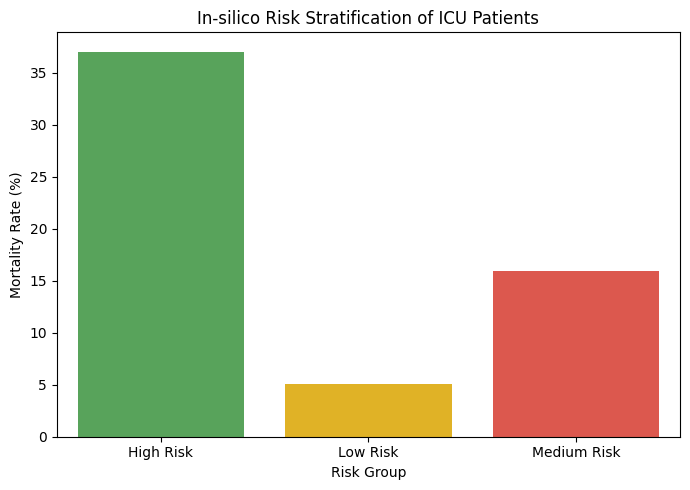

In [34]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(7,5))
sns.barplot(
    data=risk_table,
    x="Risk_Group",
    y="Mortality_Rate (%)",
    palette=["#4CAF50", "#FFC107", "#F44336"]
)

plt.ylabel("Mortality Rate (%)")
plt.xlabel("Risk Group")
plt.title("In-silico Risk Stratification of ICU Patients")
plt.tight_layout()
plt.show()


# CALIBRATION ANALYSIS

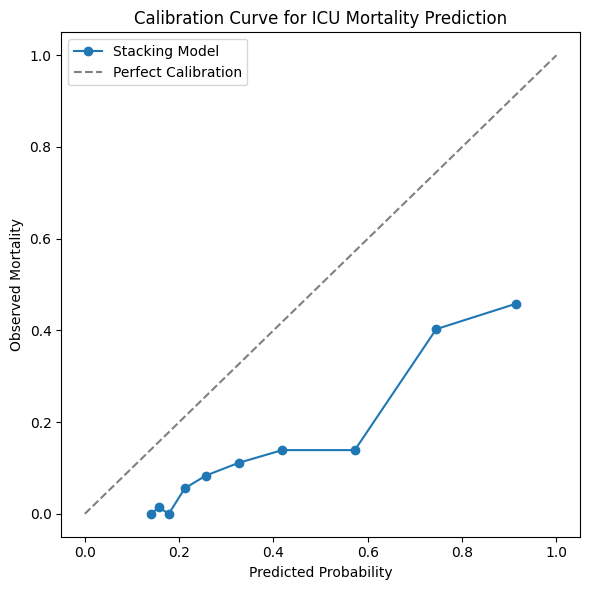

In [35]:
from sklearn.calibration import calibration_curve
import matplotlib.pyplot as plt
import numpy as np

# Calibration curve
prob_true, prob_pred = calibration_curve(
    y_test,
    stack_probs,
    n_bins=10,
    strategy='quantile'
)

plt.figure(figsize=(6,6))
plt.plot(prob_pred, prob_true, marker='o', label="Stacking Model")
plt.plot([0,1], [0,1], linestyle='--', color='gray', label="Perfect Calibration")

plt.xlabel("Predicted Probability")
plt.ylabel("Observed Mortality")
plt.title("Calibration Curve for ICU Mortality Prediction")
plt.legend()
plt.tight_layout()
plt.show()


In [36]:
calibration_table = pd.DataFrame({
    "Predicted_Probability": prob_pred,
    "Observed_Mortality": prob_true
})

calibration_table


,Predicted_Probability,Observed_Mortality
0,0.140073,0.000000
1,0.157143,0.013889
2,0.178055,0.000000
3,0.211832,0.055556
4,0.256557,0.083333
5,0.326070,0.111111
6,0.418601,0.138889
7,0.572434,0.138889
8,0.745212,0.402778
9,0.914936,0.458333


In [37]:
from sklearn.metrics import brier_score_loss

brier = brier_score_loss(y_test, stack_probs)
print("Brier Score:", round(brier, 4))


Brier Score: 0.174


# CLINICAL SUBGROUP ANALYSIS

In [38]:
subgroup_df = X_test.copy()
subgroup_df["Outcome"] = y_test.values
subgroup_df["Pred_Prob"] = stack_probs

# Age subgroup
subgroup_df["Age_Group"] = np.where(subgroup_df["Age"] < 65, "<65", "≥65")

# Ventilation subgroup
subgroup_df["Vent_Group"] = np.where(
    subgroup_df["MechVentDuration"] > 0,
    "Ventilated",
    "Not Ventilated"
)

# GCS subgroup
subgroup_df["GCS_Group"] = np.where(
    subgroup_df["GCS_last"] <= 8,
    "GCS ≤ 8",
    "GCS > 8"
)

subgroup_df[["Age_Group", "Vent_Group", "GCS_Group"]].head()


,Age_Group,Vent_Group,GCS_Group
2491,≥65,Ventilated,GCS > 8
1400,≥65,Not Ventilated,GCS > 8
4,<65,Ventilated,GCS > 8
287,<65,Ventilated,GCS > 8
2081,≥65,Ventilated,GCS ≤ 8


In [39]:
subgroup_table = subgroup_df.groupby(
    ["Age_Group", "Vent_Group", "GCS_Group"]
).agg(
    Patients=("Outcome", "count"),
    Deaths=("Outcome", "sum"),
    Mortality_Rate=("Outcome", "mean"),
    Mean_Predicted_Risk=("Pred_Prob", "mean")
).reset_index()

subgroup_table["Mortality_Rate (%)"] = (subgroup_table["Mortality_Rate"] * 100).round(2)
subgroup_table["Mean_Predicted_Risk"] = subgroup_table["Mean_Predicted_Risk"].round(3)

subgroup_table


,Age_Group,Vent_Group,GCS_Group,Patients,Deaths,Mortality_Rate,Mean_Predicted_Risk,Mortality_Rate (%)
0,<65,Not Ventilated,GCS > 8,110,7,0.063636,0.269,6.36
1,<65,Not Ventilated,GCS ≤ 8,2,0,0.000000,0.349,0.00
2,<65,Ventilated,GCS > 8,128,5,0.039062,0.263,3.91
3,<65,Ventilated,GCS ≤ 8,52,13,0.250000,0.533,25.00
4,≥65,Not Ventilated,GCS > 8,162,26,0.160494,0.374,16.05
5,≥65,Not Ventilated,GCS ≤ 8,2,1,0.500000,0.949,50.00
6,≥65,Ventilated,GCS > 8,202,26,0.128713,0.406,12.87
7,≥65,Ventilated,GCS ≤ 8,62,23,0.370968,0.742,37.10


# SUBGROUP COMPARISON PLOTS

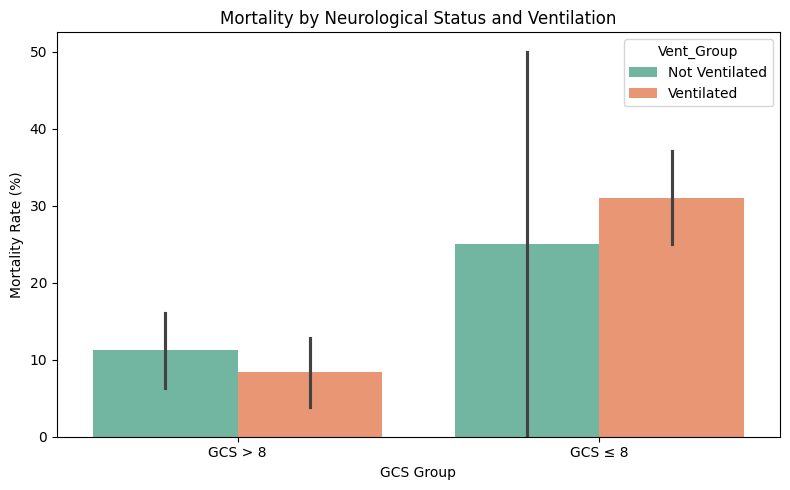

In [40]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8,5))
sns.barplot(
    data=subgroup_table,
    x="GCS_Group",
    y="Mortality_Rate (%)",
    hue="Vent_Group",
    palette="Set2"
)

plt.title("Mortality by Neurological Status and Ventilation")
plt.ylabel("Mortality Rate (%)")
plt.xlabel("GCS Group")
plt.tight_layout()
plt.show()


# Mortality by Age Group

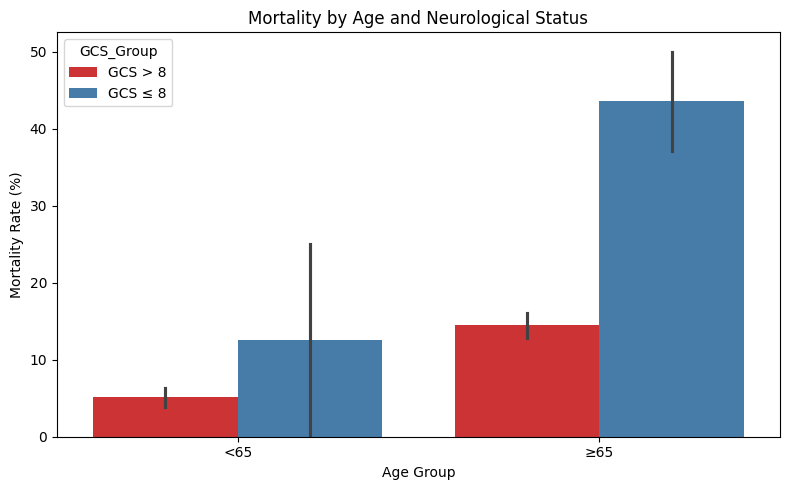

In [41]:
plt.figure(figsize=(8,5))
sns.barplot(
    data=subgroup_table,
    x="Age_Group",
    y="Mortality_Rate (%)",
    hue="GCS_Group",
    palette="Set1"
)

plt.title("Mortality by Age and Neurological Status")
plt.ylabel("Mortality Rate (%)")
plt.xlabel("Age Group")
plt.tight_layout()
plt.show()


# Decision Curve Analysis

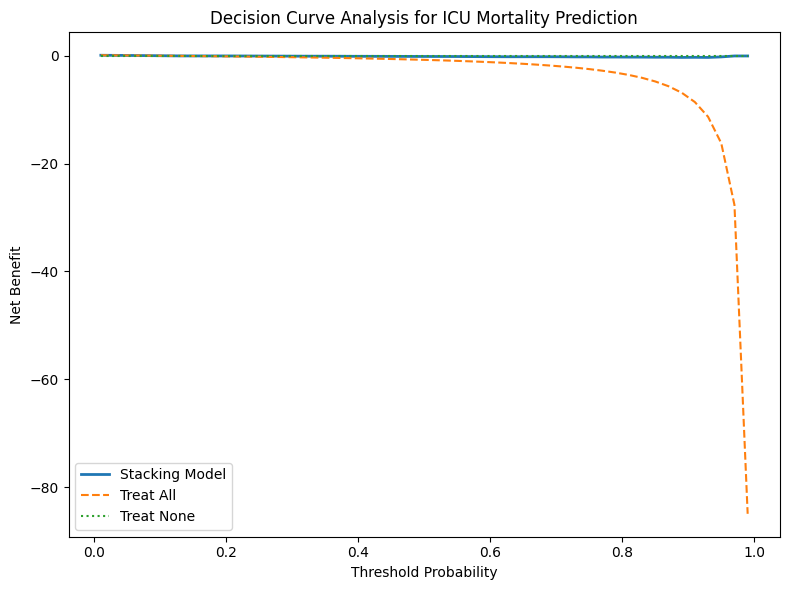

In [42]:
import numpy as np
import matplotlib.pyplot as plt

def net_benefit(y_true, y_prob, threshold):
    preds = (y_prob >= threshold).astype(int)
    tp = np.sum((preds == 1) & (y_true == 1))
    fp = np.sum((preds == 1) & (y_true == 0))
    n = len(y_true)
    return (tp / n) - (fp / n) * (threshold / (1 - threshold))

thresholds = np.linspace(0.01, 0.99, 50)

nb_model = [net_benefit(y_test.values, stack_probs, t) for t in thresholds]
nb_all = [np.mean(y_test.values) - (1 - np.mean(y_test.values)) * (t / (1 - t)) for t in thresholds]
nb_none = [0 for _ in thresholds]

plt.figure(figsize=(8,6))
plt.plot(thresholds, nb_model, label="Stacking Model", linewidth=2)
plt.plot(thresholds, nb_all, linestyle="--", label="Treat All")
plt.plot(thresholds, nb_none, linestyle=":", label="Treat None")

plt.xlabel("Threshold Probability")
plt.ylabel("Net Benefit")
plt.title("Decision Curve Analysis for ICU Mortality Prediction")
plt.legend()
plt.tight_layout()
plt.show()
